# Swedish savings accounts for an emergency fund

**Starting amount:** SEK 111,970  
**Rate snapshot:** 9 October 2026  
**Scope:** variable-rate savings accounts with no fixed holding period. The comparison highlights leading accounts, then applies deposit limits, withdrawal restrictions, fees, and deposit-guarantee coverage to the amount you gave.

Rates are variable and can change. Projections hold today’s rate constant only as a scenario; they are not forecasts. The account list is a focused shortlist from current comparison tables, not every one of the hundreds of listed products. Provider terms and eligibility should be checked again immediately before opening an account.

## How to read this comparison\n\n- The main ranking favors accounts that accept the full lump sum, have no fixed term, and permit fee-free withdrawals without a stated notice period.\n- A high headline rate may be unusable for a lump sum. Sparbanken Spira’s 2.75% account accepts only SEK 2,000 of deposits per month; the 2.75% rate applies up to a SEK 200,000 balance.\n- No fixed term is different from instant access: an account may let you request a withdrawal at any time but still take several business days to pay it to your ordinary bank. Processing time is shown separately where published.\n- Interest on Swedish bank deposits is normally taxed at 30%. The projection applies that tax to interest and assumes it is withheld when credited.\n- The state deposit guarantee is SEK 1,150,000 per person and institution from 1 January 2026. Your SEK 111,970 is below that cap at each Swedish institution in this shortlist, before adding any other balance you already hold there.\n\nThe current-rate sources do not always agree. Where a provider’s current product page exposes a rate, that is used for the model. Disagreements or rates that are available only from comparison sites are flagged in the data table.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# User inputs — edit these before rerunning.
STARTING_BALANCE_SEK = 111_970
HORIZON_YEARS = 3
INTEREST_TAX_RATE = 0.30
STATE_GUARANTEE_CAP_SEK = 1_150_000

# Optional same-day cash held at your normal transaction bank. Enter the rate
# that account actually pays; 0% is a conservative default.
INSTANT_ACCESS_RESERVE_SEK = 0
INSTANT_ACCESS_RATE_PCT = 0.00

AS_OF_DATE = "2026-10-09"
assert STARTING_BALANCE_SEK > 0
assert 0 <= INSTANT_ACCESS_RESERVE_SEK <= STARTING_BALANCE_SEK
assert 0 <= INTEREST_TAX_RATE < 1


## Shortlisted offers and terms

Offer rates below are annual rates. For a variable account, the rate can move at any time. The comparison rate snapshot is dated 9 October; product pages and comparison pages are linked per row so you can refresh the assumptions.

In [2]:
offers = pd.DataFrame([
    {
        "provider": "Moank",
        "account": "Flex Plus",
        "rate_pct": 2.52,
        "rate_display": "2.52%",
        "rate_source_quality": "Provider page",
        "minimum_sek": 10_000,
        "maximum_sek": 1_150_000,
        "monthly_deposit_cap_sek": np.nan,
        "free_withdrawals": "Unlimited",
        "withdrawal_notice_days": 0,
        "withdrawal_fee_pct": 0.0,
        "annual_fee_sek": 0,
        "payout_frequency": "annual",
        "guarantee": "Swedish state",
        "rate_source": "https://moank.com/sv/privat/sparkonto",
        "terms_source": "https://moank.com/sv/kundservice",
        "notes": "Official page shows 2.52% Flex Plus; min SEK 10,000. Daily accrual, annual capitalization. Transfers use a registered external account; timing is not stated on the product page."
    },
    {
        "provider": "Avida Bank",
        "account": "AvidaSpar / variable savings",
        "rate_pct": 2.50,
        "rate_display": "2.50% (comparison listing)",
        "rate_source_quality": "Comparison listing; verify with provider",
        "minimum_sek": 0,
        "maximum_sek": 1_150_000,
        "monthly_deposit_cap_sek": np.nan,
        "free_withdrawals": "Unlimited",
        "withdrawal_notice_days": 0,
        "withdrawal_fee_pct": 0.0,
        "annual_fee_sek": 0,
        "payout_frequency": "annual",
        "guarantee": "Swedish state",
        "rate_source": "https://www.sparkonton.se/rorlig-sparranta",
        "terms_source": "https://www.konsumenternas.se/konsumentstod/jamforelser/sparande--pension/eget-sparande/jamfor-sparkonton---rantor/jamfor-sparkonton",
        "notes": "The comparison listing shows up to 2.50% and free withdrawals. Avida's public site did not expose a current rate in this review; confirm the exact applicable rate and tier before depositing."
    },
    {
        "provider": "Plus1",
        "account": "Sparkonto Rörligt",
        "rate_pct": 2.50,
        "rate_display": "2.50%",
        "rate_source_quality": "Provider page",
        "minimum_sek": 1,
        "maximum_sek": 1_150_000,
        "monthly_deposit_cap_sek": np.nan,
        "free_withdrawals": "Unlimited",
        "withdrawal_notice_days": 0,
        "withdrawal_fee_pct": 0.0,
        "annual_fee_sek": 0,
        "payout_frequency": "annual",
        "guarantee": "Swedish state",
        "rate_source": "https://www.plus1.com/",
        "terms_source": "https://www.plus1.com/vanliga-fragor",
        "notes": "Official page shows 2.50% variable, no fixed term, and no fee for the Rörligt account. Check payout timing and withdrawal settlement before relying on it as same-day cash."
    },
    {
        "provider": "Qred Bank",
        "account": "Sparkonto Flex",
        "rate_pct": 2.40,
        "rate_display": "2.40–2.45% (model uses 2.40%)",
        "rate_source_quality": "Provider page conflict; conservative rate used",
        "minimum_sek": 0,
        "maximum_sek": 1_100_000,
        "monthly_deposit_cap_sek": np.nan,
        "free_withdrawals": "Unlimited",
        "withdrawal_notice_days": 0,
        "withdrawal_fee_pct": 0.0,
        "annual_fee_sek": 0,
        "payout_frequency": "annual",
        "guarantee": "Swedish state",
        "rate_source": "https://www.qred.se/sparkonto",
        "terms_source": "https://www.qred.se/faq/sparkonto",
        "notes": "The provider page shows 2.40% in its product description and 2.45% in its rate table. The model uses 2.40% until the rate shown at sign-up is confirmed. Qred says transfers normally take up to 3 bank days."
    },
    {
        "provider": "Froda",
        "account": "Sparkonto Flex",
        "rate_pct": 2.40,
        "rate_display": "2.40%",
        "rate_source_quality": "Daily comparison listing",
        "minimum_sek": 1,
        "maximum_sek": 1_150_000,
        "monthly_deposit_cap_sek": np.nan,
        "free_withdrawals": "Unlimited",
        "withdrawal_notice_days": 0,
        "withdrawal_fee_pct": 0.0,
        "annual_fee_sek": 0,
        "payout_frequency": "annual",
        "guarantee": "Swedish state",
        "rate_source": "https://www.sparkonton.se/rorlig-sparranta",
        "terms_source": "https://www.froda.se/",
        "notes": "Comparison listing shows 2.40% with free withdrawals and no term. Verify the live rate on Froda's account-opening page."
    },
    {
        "provider": "Lea Bank",
        "account": "Sparkonto",
        "rate_pct": 2.35,
        "rate_display": "2.35%",
        "rate_source_quality": "Provider page",
        "minimum_sek": 0,
        "maximum_sek": 1_150_000,
        "monthly_deposit_cap_sek": np.nan,
        "free_withdrawals": "Unlimited",
        "withdrawal_notice_days": 0,
        "withdrawal_fee_pct": 0.0,
        "annual_fee_sek": 0,
        "payout_frequency": "monthly",
        "guarantee": "Swedish state",
        "rate_source": "https://leabank.se/spara/sparkonto",
        "terms_source": "https://leabank.se/spara/sparkonto",
        "notes": "Official page shows 2.35%, no term, and no fees. Lea says external withdrawals normally arrive within three bank days."
    },
    {
        "provider": "Coeli Finance",
        "account": "Sparkonto rörlig ränta",
        "rate_pct": 2.30,
        "rate_display": "2.30%",
        "rate_source_quality": "Provider page",
        "minimum_sek": 10_000,
        "maximum_sek": 1_150_000,
        "monthly_deposit_cap_sek": np.nan,
        "free_withdrawals": "Unlimited",
        "withdrawal_notice_days": 0,
        "withdrawal_fee_pct": 0.0,
        "annual_fee_sek": 0,
        "payout_frequency": "annual",
        "guarantee": "Swedish state",
        "rate_source": "https://coeli.se/spara/",
        "terms_source": "https://coeli.se/allmanna-villkor-inlaning/",
        "notes": "No fixed term and no account fee; withdrawals are paid on the fifth bank day after request. Not same-day access."
    },
    {
        "provider": "Zaver",
        "account": "Flex (public account)",
        "rate_pct": 2.30,
        "rate_display": "2.30% (comparison listing; provider rate is dynamic)",
        "rate_source_quality": "Comparison listing; verify in app",
        "minimum_sek": 0,
        "maximum_sek": 1_150_000,
        "monthly_deposit_cap_sek": np.nan,
        "free_withdrawals": "Unlimited",
        "withdrawal_notice_days": 0,
        "withdrawal_fee_pct": 0.0,
        "annual_fee_sek": 0,
        "payout_frequency": "monthly",
        "guarantee": "Swedish state",
        "rate_source": "https://www.sparkonton.se/rorlig-sparranta",
        "terms_source": "https://www.zaver.com/sv-se/privat/spara",
        "notes": "The current comparison table lists the public Flex rate at 2.30%; Zaver's own rate page is rendered dynamically and did not expose the number in this review. The provider says Flex has free withdrawals, no fees, monthly interest, and a SEK 1.15m total limit."
    },
    {
        "provider": "Resurs Bank",
        "account": "Sparkonto Trygg",
        "rate_pct": 2.30,
        "rate_display": "2.30% provider / 2.55% comparison page",
        "rate_source_quality": "Conflict; provider rate used",
        "minimum_sek": 0,
        "maximum_sek": 100_000,
        "monthly_deposit_cap_sek": np.nan,
        "free_withdrawals": "3 per year",
        "withdrawal_notice_days": 0,
        "withdrawal_fee_pct": np.nan,
        "annual_fee_sek": 0,
        "payout_frequency": "annual",
        "guarantee": "Swedish state",
        "rate_source": "https://www.resursbank.se/sparkonto/sparkonto-trygg",
        "terms_source": "https://www.resursbank.se/sparkonto/sparkonto-trygg",
        "notes": "Resurs's own product page shows 2.30% up to SEK 100,000, then 0%, with three free withdrawals per year. A comparison page currently says 2.55%; use the bank's own displayed rate when opening."
    },
    {
        "provider": "Sparbanken Spira",
        "account": "Månadssparkonto",
        "rate_pct": 2.75,
        "rate_display": "2.75%",
        "rate_source_quality": "Provider page",
        "minimum_sek": 0,
        "maximum_sek": 200_000,
        "monthly_deposit_cap_sek": 2_000,
        "free_withdrawals": "Free; monthly deposit limit",
        "withdrawal_notice_days": 0,
        "withdrawal_fee_pct": 0.0,
        "annual_fee_sek": 0,
        "payout_frequency": "annual",
        "guarantee": "Swedish state",
        "rate_source": "https://www.sparbankenspira.se/privat/spara-och-placera/manadssparkonto.html",
        "terms_source": "https://www.sparbankenspira.se/privat/spara-och-placera/manadssparkonto.html",
        "notes": "Best listed flexible headline rate, but deposits are capped at SEK 2,000/month. It cannot accept the full SEK 111,970 now. The provider says free withdrawals and no binding period."
    },
    {
        "provider": "Bank Norwegian",
        "account": "Sparkonto 31",
        "rate_pct": 2.50,
        "rate_display": "2.50%",
        "rate_source_quality": "Current comparison listing",
        "minimum_sek": 0,
        "maximum_sek": 1_150_000,
        "monthly_deposit_cap_sek": np.nan,
        "free_withdrawals": "11 per year",
        "withdrawal_notice_days": 31,
        "withdrawal_fee_pct": 1.5,
        "annual_fee_sek": 0,
        "payout_frequency": "annual",
        "guarantee": "Swedish state",
        "rate_source": "https://www.konsumenternas.se/konsumentstod/jamforelser/sparande--pension/eget-sparande/jamfor-sparkonton---rantor/jamfor-sparkonton",
        "terms_source": "https://www.banknorwegian.se/spara/",
        "notes": "No fixed term, but an ordinary withdrawal is paid after 31 days. Emergency withdrawal sooner has a fee; excluded from the no-notice ranking."
    },
    {
        "provider": "Zaver",
        "account": "Premium (invitation only; conditional scenario)",
        "rate_pct": 2.70,
        "rate_display": "2.70% reported; invitation required",
        "rate_source_quality": "Comparison page; not a public offer",
        "minimum_sek": 100_000,
        "maximum_sek": 1_150_000,
        "monthly_deposit_cap_sek": np.nan,
        "free_withdrawals": "If invited: unlimited",
        "withdrawal_notice_days": 0,
        "withdrawal_fee_pct": 0.0,
        "annual_fee_sek": 0,
        "payout_frequency": "monthly",
        "guarantee": "Swedish state",
        "rate_source": "https://www.mystep.se/basta-sparrantan",
        "terms_source": "https://www.zaver.com/sv-se/privat/spara",
        "notes": "Zaver says Premium is limited and invitation-only. SEK 100,000 qualifies for a waiting list, not guaranteed access. Treat the 2.70% listing as conditional and do not include it in the base recommendation."
    },
])

offers["full_amount_can_be_placed"] = (
    (STARTING_BALANCE_SEK >= offers["minimum_sek"])
    & (STARTING_BALANCE_SEK <= offers["maximum_sek"])
    & (offers["monthly_deposit_cap_sek"].isna() | (offers["monthly_deposit_cap_sek"] >= STARTING_BALANCE_SEK))
)
offers["deposit_guarantee_covers_amount"] = STARTING_BALANCE_SEK <= STATE_GUARANTEE_CAP_SEK
# Processing time is separate from a mandatory notice period. These are the
# published transfer times found during this review; blank means not confirmed.
offers["withdrawal_processing_days"] = offers["provider"].map({
    "Qred Bank": 3,
    "Lea Bank": 3,
    "Coeli Finance": 5,
    "Zaver": 3,
})
offers["no_notice"] = offers["withdrawal_notice_days"].eq(0)
offers["unlimited_free_withdrawals"] = offers["free_withdrawals"].eq("Unlimited")
offers["simple_eligible"] = (
    offers["full_amount_can_be_placed"]
    & offers["no_notice"]
    & offers["unlimited_free_withdrawals"]
    & offers["withdrawal_fee_pct"].eq(0)
    & offers["annual_fee_sek"].eq(0)
    & offers["rate_source_quality"].ne("Comparison page; not a public offer")
)

display(offers[["provider", "account", "rate_display", "minimum_sek", "maximum_sek", "free_withdrawals", "withdrawal_notice_days", "withdrawal_processing_days", "withdrawal_fee_pct", "annual_fee_sek", "payout_frequency", "guarantee", "full_amount_can_be_placed", "rate_source_quality", "rate_source", "terms_source", "notes"]])


,provider,account,rate_display,minimum_sek,maximum_sek,free_withdrawals,withdrawal_notice_days,withdrawal_processing_days,withdrawal_fee_pct,annual_fee_sek,payout_frequency,guarantee,full_amount_can_be_placed,rate_source_quality,rate_source,terms_source,notes
0,Moank,Flex Plus,2.52%,10000,1150000,Unlimited,0,NaN,0.0,0,annual,Swedish state,True,Provider page,https://moank.com/sv/privat/sparkonto,https://moank.com/sv/kundservice,Official page shows 2.52% Flex Plus; min SEK 1...
1,Avida Bank,AvidaSpar / variable savings,2.50% (comparison listing),0,1150000,Unlimited,0,NaN,0.0,0,annual,Swedish state,True,Comparison listing; verify with provider,https://www.sparkonton.se/rorlig-sparranta,https://www.konsumenternas.se/konsumentstod/ja...,The comparison listing shows up to 2.50% and f...
2,Plus1,Sparkonto Rörligt,2.50%,1,1150000,Unlimited,0,NaN,0.0,0,annual,Swedish state,True,Provider page,https://www.plus1.com/,https://www.plus1.com/vanliga-fragor,"Official page shows 2.50% variable, no fixed t..."
3,Qred Bank,Sparkonto Flex,2.40–2.45% (model uses 2.40%),0,1100000,Unlimited,0,3.0,0.0,0,annual,Swedish state,True,Provider page conflict; conservative rate used,https://www.qred.se/sparkonto,https://www.qred.se/faq/sparkonto,The provider page shows 2.40% in its product d...
4,Froda,Sparkonto Flex,2.40%,1,1150000,Unlimited,0,NaN,0.0,0,annual,Swedish state,True,Daily comparison listing,https://www.sparkonton.se/rorlig-sparranta,https://www.froda.se/,Comparison listing shows 2.40% with free withd...
5,Lea Bank,Sparkonto,2.35%,0,1150000,Unlimited,0,3.0,0.0,0,monthly,Swedish state,True,Provider page,https://leabank.se/spara/sparkonto,https://leabank.se/spara/sparkonto,"Official page shows 2.35%, no term, and no fee..."
6,Coeli Finance,Sparkonto rörlig ränta,2.30%,10000,1150000,Unlimited,0,5.0,0.0,0,annual,Swedish state,True,Provider page,https://coeli.se/spara/,https://coeli.se/allmanna-villkor-inlaning/,No fixed term and no account fee; withdrawals ...
7,Zaver,Flex (public account),2.30% (comparison listing; provider rate is dy...,0,1150000,Unlimited,0,3.0,0.0,0,monthly,Swedish state,True,Comparison listing; verify in app,https://www.sparkonton.se/rorlig-sparranta,https://www.zaver.com/sv-se/privat/spara,The current comparison table lists the public ...
8,Resurs Bank,Sparkonto Trygg,2.30% provider / 2.55% comparison page,0,100000,3 per year,0,NaN,NaN,0,annual,Swedish state,False,Conflict; provider rate used,https://www.resursbank.se/sparkonto/sparkonto-...,https://www.resursbank.se/sparkonto/sparkonto-...,Resurs's own product page shows 2.30% up to SE...
9,Sparbanken Spira,Månadssparkonto,2.75%,0,200000,Free; monthly deposit limit,0,NaN,0.0,0,annual,Swedish state,False,Provider page,https://www.sparbankenspira.se/privat/spara-oc...,https://www.sparbankenspira.se/privat/spara-oc...,"Best listed flexible headline rate, but deposi..."


## Estimated returns on SEK 111,970

For monthly-credit accounts, the model converts the quoted effective annual rate into a monthly rate, with 30% withheld from each credit and the net credited interest reinvested. For annual-credit accounts, it applies 30% to the annual interest and reinvests the net once per year. Any amount that cannot be placed in the account (for example, Spira’s monthly deposit cap) stays at 0% in this single-account illustration. Fees are shown separately and are not silently assumed to be zero when their terms are unclear.

In [3]:
def after_tax_ending_value(principal, annual_rate_pct, payout_frequency, years, tax_rate=INTEREST_TAX_RATE):
    """Scenario value assuming a constant effective annual rate and tax at crediting."""
    periods_per_year = 12 if payout_frequency == "monthly" else 1
    gross_period_rate = (1 + annual_rate_pct / 100) ** (1 / periods_per_year) - 1
    net_period_rate = gross_period_rate * (1 - tax_rate)
    return principal * (1 + net_period_rate) ** (periods_per_year * years)

def placed_principal(row):
    if STARTING_BALANCE_SEK < row["minimum_sek"]:
        return 0.0
    amount = min(STARTING_BALANCE_SEK, row["maximum_sek"])
    if pd.notna(row["monthly_deposit_cap_sek"]):
        amount = min(amount, row["monthly_deposit_cap_sek"])
    return float(amount)

projection_rows = []
for _, offer in offers.iterrows():
    placed = placed_principal(offer)
    unplaced = STARTING_BALANCE_SEK - placed
    for years in sorted(set([1, HORIZON_YEARS])):
        ending = after_tax_ending_value(placed, offer["rate_pct"], offer["payout_frequency"], years)
        ending += unplaced  # unplaced balance is modeled at 0% until assigned elsewhere
        projection_rows.append({
            "provider": offer["provider"],
            "account": offer["account"],
            "years": years,
            "rate_used_pct": offer["rate_pct"],
            "amount_earning_rate_sek": placed,
            "amount_unplaced_at_0pct_sek": unplaced,
            "estimated_net_interest_sek": ending - STARTING_BALANCE_SEK,
            "estimated_ending_value_sek": ending,
            "simple_eligible": bool(offer["simple_eligible"]),
            "rate_source_quality": offer["rate_source_quality"],
        })

projections = pd.DataFrame(projection_rows)
one_year = projections[projections["years"] == 1].copy()
eligible_rank = one_year[one_year["simple_eligible"]].sort_values("estimated_net_interest_sek", ascending=False)
if eligible_rank.empty:
    raise ValueError("No account meets the selected no-lock, full-deposit, fee-free criteria.")
best_eligible = eligible_rank.iloc[0]
one_year["rank among eligible"] = np.nan
one_year.loc[eligible_rank.index, "rank among eligible"] = np.arange(1, len(eligible_rank) + 1)
display(one_year.sort_values(["simple_eligible", "estimated_net_interest_sek"], ascending=[False, False]).style.format({
    "rate_used_pct": "{:.2f}%",
    "amount_earning_rate_sek": "{:,.0f}",
    "amount_unplaced_at_0pct_sek": "{:,.0f}",
    "estimated_net_interest_sek": "{:,.0f}",
    "estimated_ending_value_sek": "{:,.0f}",
    "rank among eligible": "{:.0f}",
}))


,provider,account,years,rate_used_pct,amount_earning_rate_sek,amount_unplaced_at_0pct_sek,estimated_net_interest_sek,estimated_ending_value_sek,simple_eligible,rate_source_quality,rank among eligible
0,Moank,Flex Plus,1,2.52%,"111,970",0,"1,975","113,945",True,Provider page,1
2,Avida Bank,AvidaSpar / variable savings,1,2.50%,"111,970",0,"1,959","113,929",True,Comparison listing; verify with provider,2
4,Plus1,Sparkonto Rörligt,1,2.50%,"111,970",0,"1,959","113,929",True,Provider page,3
6,Qred Bank,Sparkonto Flex,1,2.40%,"111,970",0,"1,881","113,851",True,Provider page conflict; conservative rate used,4
8,Froda,Sparkonto Flex,1,2.40%,"111,970",0,"1,881","113,851",True,Daily comparison listing,5
10,Lea Bank,Sparkonto,1,2.35%,"111,970",0,"1,836","113,806",True,Provider page,6
12,Coeli Finance,Sparkonto rörlig ränta,1,2.30%,"111,970",0,"1,803","113,773",True,Provider page,7
14,Zaver,Flex (public account),1,2.30%,"111,970",0,"1,797","113,767",True,Comparison listing; verify in app,8
22,Zaver,Premium (invitation only; conditional scenario),1,2.70%,"111,970",0,"2,108","114,078",False,Comparison page; not a public offer,nan
20,Bank Norwegian,Sparkonto 31,1,2.50%,"111,970",0,"1,959","113,929",False,Current comparison listing,nan


## Best combinations for this amount

A split is useful only if it buys something you value, such as same-day access, a meaningful deposit-rate tier, or diversification across institutions. It does not increase the state-guarantee cap for this amount: SEK 111,970 is far below SEK 1,150,000 at one Swedish institution.

In [4]:
best_offer_row = offers.loc[offers["account"].eq(best_eligible["account"])].iloc[0]
best_rate = float(best_offer_row["rate_pct"])
best_frequency = best_offer_row["payout_frequency"]

# Optional split: use the allowed first-month Spira deposit, then place the rest
# in the best fully eligible offer. This assumes Spira accepts a SEK 2,000 initial deposit.
spira = offers.loc[offers["provider"].eq("Sparbanken Spira")].iloc[0]
spira_amount = min(STARTING_BALANCE_SEK, float(spira["monthly_deposit_cap_sek"]))
spira_amount = min(spira_amount, float(spira["maximum_sek"]))
remainder = STARTING_BALANCE_SEK - spira_amount

def combo_ending_value(reserve_amount, reserve_rate_pct, years):
    main_amount = STARTING_BALANCE_SEK - reserve_amount
    return (
        after_tax_ending_value(reserve_amount, reserve_rate_pct, "annual", years)
        + after_tax_ending_value(main_amount, best_rate, best_frequency, years)
    )

combo_rows = []
for years in sorted(set([1, HORIZON_YEARS])):
    best_single_end = after_tax_ending_value(STARTING_BALANCE_SEK, best_rate, best_frequency, years)
    spira_combo_end = (
        after_tax_ending_value(spira_amount, spira["rate_pct"], spira["payout_frequency"], years)
        + after_tax_ending_value(remainder, best_rate, best_frequency, years)
    )
    combo_rows.extend([
        {"scenario": f"All in {best_offer_row['provider']} {best_offer_row['account']}", "years": years, "ending_value_sek": best_single_end},
        {"scenario": f"SEK {spira_amount:,.0f} Spira + rest in {best_offer_row['provider']}", "years": years, "ending_value_sek": spira_combo_end},
    ])
    for reserve in [0, 5_000, 10_000, 20_000]:
        if reserve <= STARTING_BALANCE_SEK:
            combo_rows.append({
                "scenario": f"SEK {reserve:,.0f} same-day reserve at {INSTANT_ACCESS_RATE_PCT:.2f}% + rest in {best_offer_row['provider']}",
                "years": years,
                "ending_value_sek": combo_ending_value(reserve, INSTANT_ACCESS_RATE_PCT, years),
            })

combinations = pd.DataFrame(combo_rows)
combinations["net_interest_sek"] = combinations["ending_value_sek"] - STARTING_BALANCE_SEK
display(combinations[combinations["years"] == 1].sort_values("ending_value_sek", ascending=False).style.format({
    "ending_value_sek": "SEK {:,.0f}",
    "net_interest_sek": "SEK {:,.0f}",
}))

best_single_interest = float(best_eligible["estimated_net_interest_sek"])
small_rate_gap_net_sek = STARTING_BALANCE_SEK * (best_rate - 2.50) / 100 * (1 - INTEREST_TAX_RATE)
print(f"Current model leader among fully eligible offers: {best_offer_row['provider']} {best_offer_row['account']} at {best_rate:.2f}%.")
print(f"Estimated net interest over 1 year at a constant rate: SEK {best_single_interest:,.0f}.")
print(f"After-tax annual difference versus a 2.50% offer on the full balance: about SEK {small_rate_gap_net_sek:,.0f}.")
print(f"Putting only SEK {spira_amount:,.0f} into Spira and the rest in the model leader changes the one-year net by only about SEK {float(combinations[(combinations['years'] == 1) & combinations['scenario'].str.startswith('SEK 2,000 Spira')]['net_interest_sek'].iloc[0] - best_single_interest):,.0f} under the constant-rate assumption.")


,scenario,years,ending_value_sek,net_interest_sek
1,"SEK 2,000 Spira + rest in Moank",1,"SEK 113,948","SEK 1,978"
0,All in Moank Flex Plus,1,"SEK 113,945","SEK 1,975"
2,SEK 0 same-day reserve at 0.00% + rest in Moank,1,"SEK 113,945","SEK 1,975"
3,"SEK 5,000 same-day reserve at 0.00% + rest in Moank",1,"SEK 113,857","SEK 1,887"
4,"SEK 10,000 same-day reserve at 0.00% + rest in Moank",1,"SEK 113,769","SEK 1,799"
5,"SEK 20,000 same-day reserve at 0.00% + rest in Moank",1,"SEK 113,592","SEK 1,622"


Current model leader among fully eligible offers: Moank Flex Plus at 2.52%.
Estimated net interest over 1 year at a constant rate: SEK 1,975.
After-tax annual difference versus a 2.50% offer on the full balance: about SEK 16.
Putting only SEK 2,000 into Spira and the rest in the model leader changes the one-year net by only about SEK 3 under the constant-rate assumption.


## Dynamic conclusion

The next cell writes the conclusion from the current input table and amount. It distinguishes the highest headline rate from the best account that can accept the whole lump sum under the selected no-lock and fee-free criteria.

In [5]:
headline = offers.sort_values("rate_pct", ascending=False).iloc[0]
eligible_top = eligible_rank.iloc[0]
eligible_account = offers.loc[offers["account"].eq(eligible_top["account"])].iloc[0]
horizon_projection = projections[
    (projections["account"] == eligible_top["account"])
    & (projections["years"] == HORIZON_YEARS)
].iloc[0]

print(f"Highest headline rate in this shortlist: {headline['provider']} {headline['account']} at {headline['rate_display']}.")
print(f"Best modeled one-account fit for SEK {STARTING_BALANCE_SEK:,.0f}: {eligible_account['provider']} {eligible_account['account']} at {eligible_account['rate_pct']:.2f}%.")
print(f"Estimated net interest after {HORIZON_YEARS} year(s), if that variable rate stayed unchanged: SEK {horizon_projection['estimated_net_interest_sek']:,.0f}.")
print(f"The best 2.50% alternatives are only about SEK {small_rate_gap_net_sek:,.0f} net per year behind the model leader; this is a small financial difference.")
print("For an emergency fund, choose how much must be spendable immediately and keep that part in your everyday bank account. The rest can sit in the highest-rate no-lock account that passes your own transfer-speed and account-eligibility checks.")
print("The rate ranking is not a forecast: variable rates may change, and provider eligibility, transfer time, current fees, and existing balances under each institution's guarantee cap should be checked before depositing.")


Highest headline rate in this shortlist: Sparbanken Spira Månadssparkonto at 2.75%.
Best modeled one-account fit for SEK 111,970: Moank Flex Plus at 2.52%.
Estimated net interest after 3 year(s), if that variable rate stayed unchanged: SEK 6,031.
The best 2.50% alternatives are only about SEK 16 net per year behind the model leader; this is a small financial difference.
For an emergency fund, choose how much must be spendable immediately and keep that part in your everyday bank account. The rest can sit in the highest-rate no-lock account that passes your own transfer-speed and account-eligibility checks.
The rate ranking is not a forecast: variable rates may change, and provider eligibility, transfer time, current fees, and existing balances under each institution's guarantee cap should be checked before depositing.


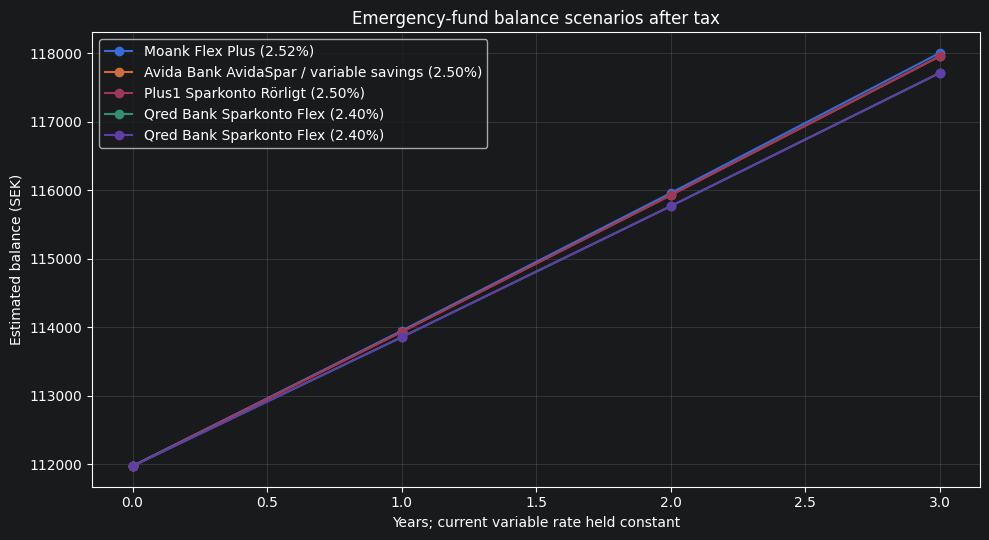

In [6]:
plot_years = np.arange(HORIZON_YEARS + 1)
plt.figure(figsize=(10, 5.5))
for _, offer in eligible_rank.head(5).iterrows():
    offer_row = offers.loc[offers["account"].eq(offer["account"])].iloc[0]
    values = [after_tax_ending_value(STARTING_BALANCE_SEK, offer_row["rate_pct"], offer_row["payout_frequency"], int(y)) for y in plot_years]
    plt.plot(plot_years, values, marker="o", label=f"{offer_row['provider']} {offer_row['account']} ({offer_row['rate_pct']:.2f}%)")
plt.title("Emergency-fund balance scenarios after tax")
plt.xlabel("Years; current variable rate held constant")
plt.ylabel("Estimated balance (SEK)")
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()


## Sources and model limits

- [Sparkonton.se variable-rate comparison](https://www.sparkonton.se/rorlig-sparranta), shown as updated 9 October 2026; used to identify the current shortlist and to flag rate differences.
- [MyStep October 2026 comparison](https://www.mystep.se/basta-sparrantan), updated 7 October 2026; includes an advertised Zaver variable rate, but does not distinguish the public Flex product from limited-access Premium in its headline list.
- [Moank savings account and current rates](https://moank.com/sv/privat/sparkonto) and [Moank customer-service terms](https://moank.com/sv/kundservice).
- [Sparbanken Spira Månadssparkonto](https://www.sparbankenspira.se/privat/spara-och-placera/manadssparkonto.html).
- [Plus1 savings accounts](https://www.plus1.com/) and [Plus1 FAQ](https://www.plus1.com/vanliga-fragor).
- [Qred Sparkonto Flex](https://www.qred.se/sparkonto) and [Qred account FAQ](https://www.qred.se/faq/sparkonto).
- [Lea Bank Sparkonto](https://leabank.se/spara/sparkonto).
- [Coeli variable-rate savings](https://coeli.se/spara/) and [Coeli deposit-account terms](https://coeli.se/allmanna-villkor-inlaning/).
- [Resurs Sparkonto Trygg](https://www.resursbank.se/sparkonto/sparkonto-trygg).
- [Zaver savings accounts and Premium access](https://www.zaver.com/sv-se/privat/spara).
- [Skatteverket: tax on interest income](https://www.skatteverket.se/privat/etjansterochblanketter/svarpavanligafragor/rantorochutdelning/privatrantorfaq/vilkaskattereglergallerforranteinkomsterochutdelningar.5.18e1b10334ebe8bc8000118462.html).
- [Riksgälden: 2026 deposit-guarantee cap](https://www.riksgalden.se/press-och-publicerat/pressmeddelanden-och-nyheter/pressmeddelanden/2025/insattningsgarantins-maxbelopp-andras-till-1-150-000-kronor/).

Rates and terms were reviewed for 9 October 2026. Some live provider pages hide rates behind account login or dynamic page elements; those rows are explicitly marked as comparison-source inputs. Rates, eligibility, deposit limits, transfer speeds, and guarantees can change. This notebook does not include inflation, interest-rate changes, account-switching delays, or the value of immediate card/payment access.